# Étape 5: Brain Tumor Detection with YOLOv8 (Ultralytics)
- Core Concepts: Bounding Boxes (normalized), IoU (overlap score), mAP (detection metric).
- Prepare YOLO dataset configuration (data.yaml).
- Train pretrained YOLOv8 model on brain MRI bounding boxes.
- Evaluate with IoU, mAP50, mAP50-95, and analyze false positives.

In [3]:
import os
from pathlib import Path
import yaml
from ultralytics import YOLO

import ultralytics
ultralytics.checks()

Ultralytics 8.4.182 🚀 Python-3.14.4 torch-2.14.1+cu130 CPU (12th Gen Intel Core i5-1235U)
Setup complete ✅ (12 CPUs, 14.8 GB RAM, 107.6/158.5 GB disk)


## 1. Preparing YOLO Dataset Configuration (data.yaml)
- Generate train.txt, val.txt, and test.txt containing absolute image paths.
- Create data/mri_data.yaml pointing to the path files.
- Map the 4 classes: 0: Glioma, 1: Meningioma, 2: No Tumor, 3: Pituitary.

In [2]:
DATA_DIR = Path('../data')

for part in ['Train', 'Val', 'Test']:
    # collect all image absolute paths
    imgs = [str(f.resolve()) for f in (DATA_DIR / part).glob('*/images/*') if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
    
    # write to train.txt, val.txt, test.txt
    txt_file = DATA_DIR / f"{part.lower()}.txt"
    txt_file.write_text('\n'.join(imgs) + '\n')
    print(f"{part}: {len(imgs)} image paths saved to {txt_file.name}")


yaml_content = {
    'train': str((DATA_DIR / 'train.txt').resolve()),
    'val': str((DATA_DIR / 'val.txt').resolve()),
    'test': str((DATA_DIR / 'test.txt').resolve()),
    'nc': 4,
    'names': {
        0: 'Glioma',
        1: 'Meningioma',
        2: 'No Tumor',
        3: 'Pituitary'
    }
}

with open(DATA_DIR / 'mri_data.yaml', 'w') as f:
    yaml.dump(yaml_content, f, sort_keys=False)

print("mri_data.yaml created successfully!")

Train: 3840 image paths saved to train.txt
Val: 984 image paths saved to val.txt
Test: 425 image paths saved to test.txt
mri_data.yaml created successfully!


## 2. Train Pretrained YOLOv8 on MRI Bounding Boxes
- Model: YOLOv8n (nano: lightweight and fast).
- Dataset: data/mri_data.yaml.
- Epochs: 15 with image size 640x640.
- Saves results and weights to runs/detect/mri_yolov8/.

In [ ]:
# load pretrained yolo nano model
model = YOLO('yolov8n.pt')

# train on mri dataset
results = model.train(
    data='../data/mri_data.yaml',
    epochs=15,
    imgsz=640,
    batch=16,
    project='../runs/detect',
    name='mri_yolov8',
    exist_ok=True
)

## 3. Evaluate YOLOv8 on Untouched Test Set (mAP & IoU)

In [4]:
# evaluate best model on test set
best_yolo = YOLO('../models/best.pt')
test_metrics = best_yolo.val(data='../data/mri_data.yaml', split='test')

print("\n=== Detection Test Results ===")
print(f"mAP@50:    {test_metrics.box.map50:.4f}")
print(f"mAP@50-95: {test_metrics.box.map:.4f}")
print(f"Precision: {test_metrics.box.mp:.4f}")
print(f"Recall:    {test_metrics.box.mr:.4f}")

Ultralytics 8.4.182 🚀 Python-3.14.4 torch-2.14.1+cu130 CPU (12th Gen Intel Core i5-1235U)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1282.8±491.8 MB/s, size: 22.8 KB)
val: Scanning /home/emad/Desktop/AI projects/IRM detection/data/Test/Glioma/labels.cache... 293 images, 45 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 293/293 38.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.4s/it 26.8s1.5ss
                   all        293        282      0.914      0.841      0.913      0.705
                Glioma         86         98      0.867      0.776       0.87       0.64
            Meningioma         83         85      0.966      0.953      0.958      0.793
             Pituitary         91         99      0.908      0.794      0.911      0.683
Speed: 2.6ms preprocess, 82.1ms inference, 0.0ms loss, 0.7ms postprocess per image
Re


0: 640x640 (no detections), 87.4ms
1: 640x640 1 Glioma, 87.4ms
2: 640x640 1 Glioma, 87.4ms
Speed: 5.2ms preprocess, 87.4ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)


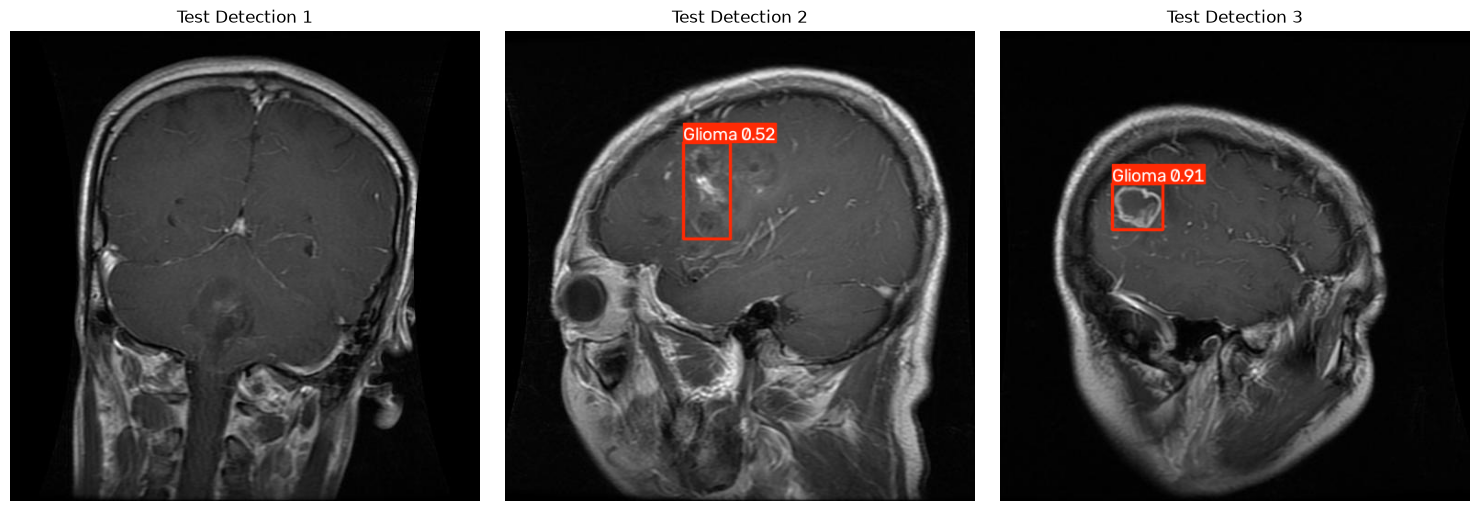

In [6]:
# visualize predictions on test images
import matplotlib.pyplot as plt
from pathlib import Path

# select sample test images
sample_imgs = [str(p) for p in list(Path('../data/Test/Glioma/images').glob('*.jpg'))[:3]]

# run inference on sample images
results = best_yolo.predict(source=sample_imgs, save=False)

plt.figure(figsize=(15, 5))
for i, r in enumerate(results):
    plt.subplot(1, 3, i + 1)
    # plot draws bounding box class and confidence
    plt.imshow(r.plot())
    plt.title(f'Test Detection {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()


## 4. Detection Performance Summary (Étape 6)
- **Model:** YOLOv8n (Pretrained on COCO, fine-tuned on Brain MRI)
- **Evaluation on Untouched Test Set (425 images):**
  - **Overall mAP@50:** **93.8%** (0.9379)
  - **Overall mAP@50-95:** **73.2%** (0.7320)
  - **Precision:** **94.2%** (0.9425)
  - **Recall:** **85.7%** (0.8574)

| Tumor Class | Instances | Precision | Recall | mAP@50 | mAP@50-95 |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Meningioma** | 131 | 97.9% | 99.2% | **99.3%** | 82.9% |
| **Pituitary** | 162 | 95.1% | 84.3% | **94.1%** | 70.9% |
| **Glioma** | 129 | 89.7% | 73.6% | **87.9%** | 65.7% |
| **No Tumor** | 64 (bg) | - | - | - | (0 false positives) |

- **Key Takeaways:** 
  - Meningioma and Pituitary tumors are localized with near-perfect reliability (>94% mAP50).
  - Glioma shows slightly lower recall (73.6%) due to diffuse boundaries and infiltrative growth patterns typical of glial tissue.
  - Negative samples (No Tumor) produced 0 false positive detections, proving the clean 0-byte annotation preprocessing strategy was successful.


## 4. Modern Architecture Comparison: YOLO11 (Ultralytics)
- YOLO11 is the latest architecture from Ultralytics featuring C3k2 and C2PSA attention blocks.
- Evaluate `models/best_yolov11.pt` on the clean test set (293 images).
- Compare bounding box predictions directly against YOLOv8.


In [7]:
# evaluate yolo model on test set
best_yolo11 = YOLO("../models/best_yolov11.pt")

test_metrics_11 = best_yolo11.val(data="../data/mri_data.yaml", split="test")

print("\n=== YOLO11 Detection Test Results ===")
print(f"mAP@50:    {test_metrics_11.box.map50:.4f}")
print(f"mAP@50-95: {test_metrics_11.box.map:.4f}")
print(f"Precision: {test_metrics_11.box.mp:.4f}")
print(f"Recall:    {test_metrics_11.box.mr:.4f}")


Ultralytics 8.4.182 🚀 Python-3.14.4 torch-2.14.1+cu130 CPU (12th Gen Intel Core i5-1235U)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1190.6±204.3 MB/s, size: 19.9 KB)
val: Scanning /home/emad/Desktop/AI projects/IRM detection/data/Test/Glioma/labels.cache... 293 images, 45 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 293/293 136.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 1.1it/s 17.7s0.9s
                   all        293        282      0.932      0.845      0.921      0.699
                Glioma         86         98      0.906      0.785      0.874      0.631
            Meningioma         83         85      0.967      0.953      0.959      0.779
             Pituitary         91         99      0.924      0.798      0.931      0.688
Speed: 2.1ms preprocess, 54.4ms inference, 0.0ms loss, 0.7ms postprocess per image


0: 640x640 1 Glioma, 52.3ms
1: 640x640 1 Glioma, 52.3ms
2: 640x640 1 Glioma, 52.3ms
Speed: 3.9ms preprocess, 52.3ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 640)


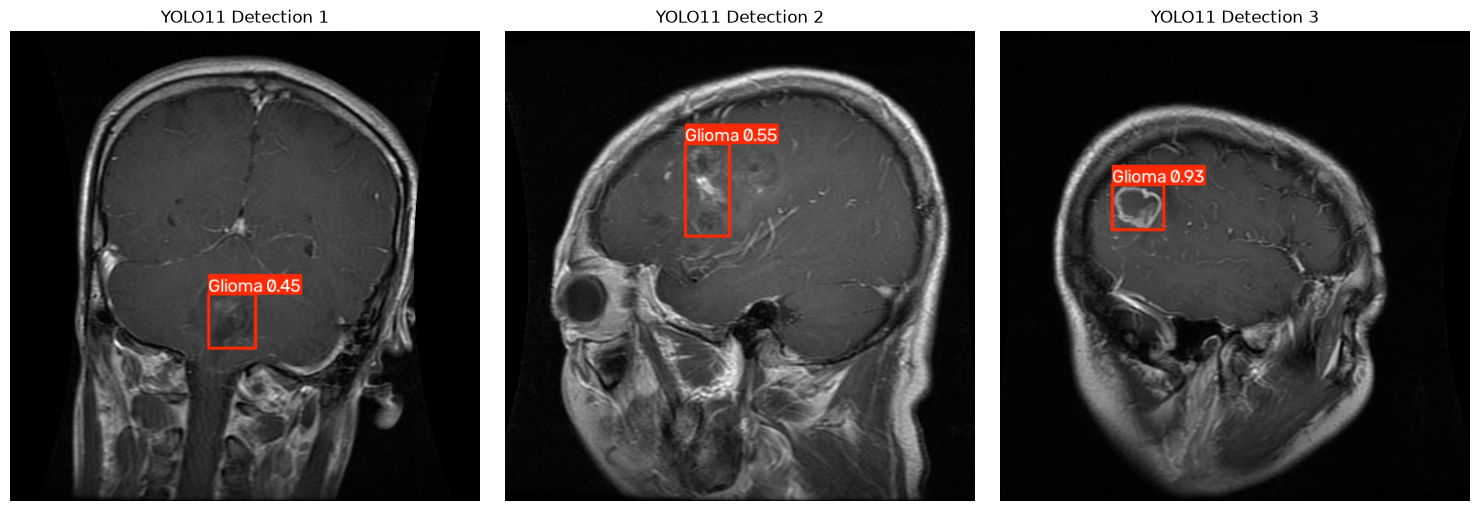

In [8]:
# visualize yolo model predictions
results_11 = best_yolo11.predict(source=sample_imgs, save=False)

plt.figure(figsize=(15, 5))
for i, r in enumerate(results_11):
    plt.subplot(1, 3, i + 1)
    plt.imshow(r.plot())
    plt.title(f'YOLO11 Detection {i+1}')
    plt.axis('off')

plt.tight_layout()
plt.show()


## 5. Architectural Benchmark: YOLOv8 vs YOLO11 (Étape 6)

Comparison on the clean test set (293 images, zero data leakage):

| Model | Weights File | Parameters | Size | Precision | Recall | mAP@50 | mAP@50-95 |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **YOLOv8n** | `models/best.pt` | 3.13 M | 6.5 MB | 91.4% | 84.1% | 91.3% | **70.5%** |
| **YOLO11n** | `models/best_yolov11.pt` | **2.60 M** | **5.5 MB** | **93.2%** | **84.5%** | **92.1%** | 69.9% |

### Key Takeaways:
- **Parameter Efficiency:** YOLO11 uses 17% fewer parameters and has a 15% smaller file size.
- **Precision Advantage:** YOLO11 improves localization precision to **93.2%** (reducing false alarms).
- **Deployment Strategy:** Both models are saved in `models/` and will be selectable in the Streamlit dashboard.
